## Load Dependencies

In [ ]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests

## Load Dataset

In [ ]:
fashion_mnist = tf.keras.datasets.fashion_mnist
(train_images,train_labels),(test_images,test_labels) = fashion_mnist.load_data()
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
print("The train images are of shape ",train_images.shape)
print("The train labels are of shape ",train_labels.shape)
print("The test images are of shape ",test_images.shape)
print("The test labels are of shape ",test_labels.shape)


The train images are of shape  (60000, 28, 28)
The train labels are of shape  (60000,)
The test images are of shape  (10000, 28, 28)
The test labels are of shape  (10000,)


## Training a simple CNN Classifier from Scratch

### Reshaping Image Data for Modeling

In [ ]:
train_images_reshaped = train_images.reshape(train_images.shape[0],28,28,1)
test_images_reshaped = test_images.reshape(test_images.shape[0],28,28,1)



### Plotting the Images from the dataset

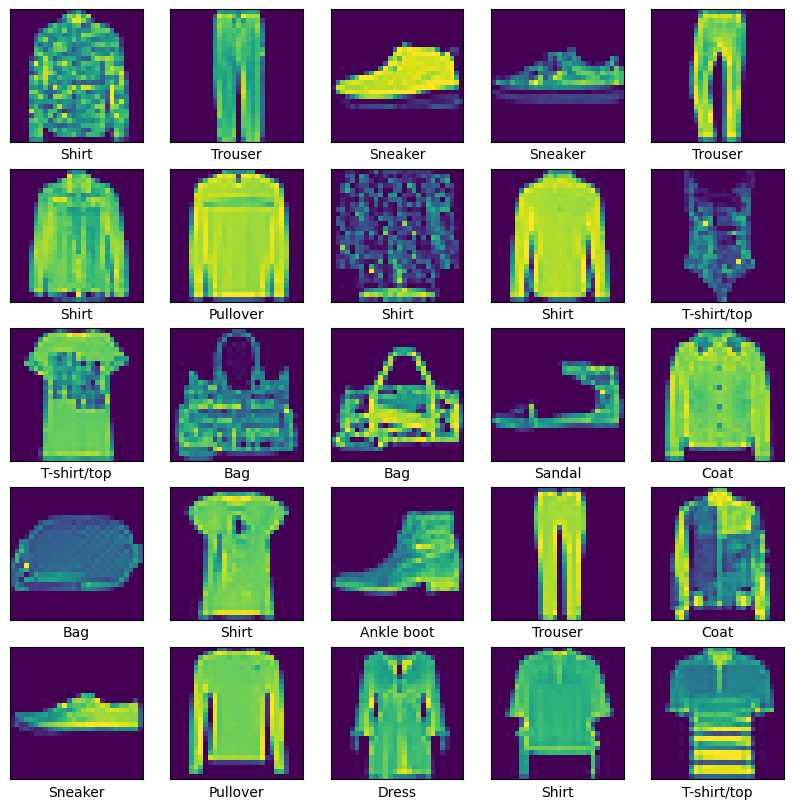

In [ ]:
import random
plt.figure(figsize = (10,10))
for i in range(25):
  random_no = random.randint(0,60000)
  plt.subplot(5,5,i+1)
  plt.xticks([])
  plt.yticks([])
  plt.grid(False)
  plt.imshow(train_images[random_no])
  plt.xlabel(class_names[train_labels[random_no]])
plt.show()

### Build a CNN Model Architecture

In [ ]:
Input_shape = (28,28,1)
model = tf.keras.models.Sequential()
#define conv-pool layers -set1
model.add(tf.keras.layers.Conv2D(filters = 16,kernel_size = (3,3),strides = (1,1),activation = "relu", padding = "valid",input_shape = Input_shape))
model.add(tf.keras.layers.MaxPooling2D(pool_size = (2,2)))
#define conv-pool layers -set2
model.add(tf.keras.layers.Conv2D(filters = 32,kernel_size = (3,3),strides = (1,1),activation = "relu",padding = "valid",input_shape = Input_shape))
model.add(tf.keras.layers.MaxPooling2D(pool_size = (2,2)))
#add flatten layer
model.add(tf.keras.layers.Flatten())
# Adding dense layers with some drop out
model.add(tf.keras.layers.Dense(256,activation = "relu"))
model.add(tf.keras.layers.Dropout(0.3))
model.add(tf.keras.layers.Dense(128,activation = "relu"))
model.add(tf.keras.layers.Dropout(0.3))
# adding an output layer
model.add(tf.keras.layers.Dense(10,activation = "softmax"))

/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


#### Model Structure

In [ ]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 26, 26, 16)          │             160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 13, 13, 16)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 11, 11, 32)          │           4,640 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 5, 5, 32)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 800)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 256)                 │         205,056 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_3 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 244,042 (953.29 KB)

 Trainable params: 244,042 (953.29 KB)

 Non-trainable params: 0 (0.00 B)

#### Plotting the model

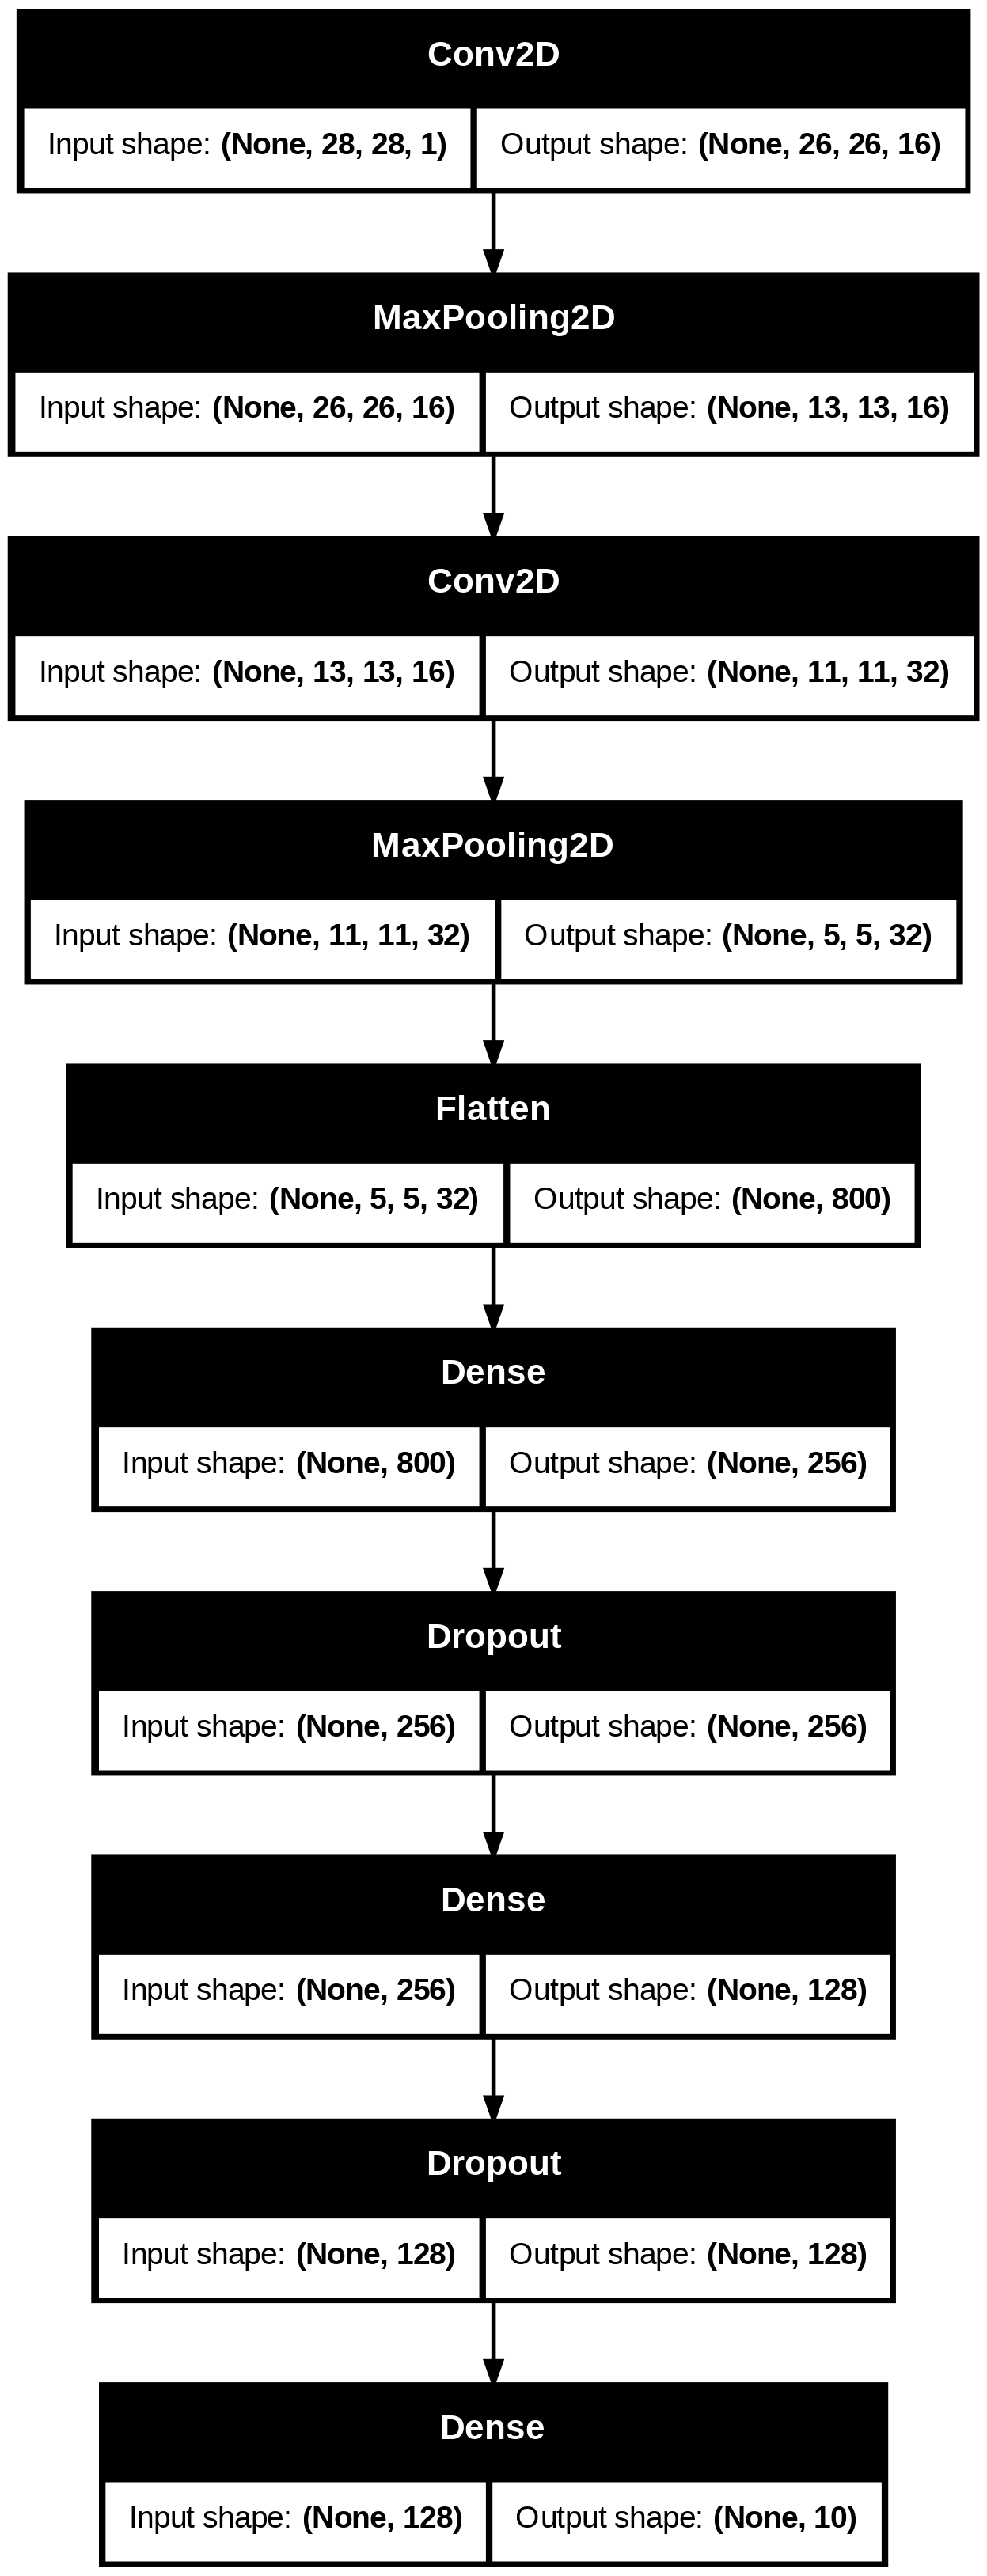

In [ ]:
from tensorflow.keras.utils import plot_model
plot_model(model,show_shapes = True)

#### Compile model

In [ ]:
model.compile(optimizer = "adam",loss = 'sparse_categorical_crossentropy',metrics = ["accuracy"])

### Model Training

In [ ]:
train_images_scaled = train_images_reshaped/255.0
test_images_scaled = test_images_reshaped/255.0
from tensorflow.keras import callbacks
from tensorflow.keras.callbacks import EarlyStopping
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = "val_l0oss",patience = 2,restore_best_weights=True,verbose = 1)
history = model.fit(train_images_scaled,train_labels, batch_size =32, epochs=50,callbacks=[early_stopping],validation_split=0.2,verbose = 1)
history

Epoch 1/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - accuracy: 0.6965 - loss: 0.8256 - val_accuracy: 0.8508 - val_loss: 0.3991
Epoch 2/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8518 - loss: 0.4041 - val_accuracy: 0.8732 - val_loss: 0.3321
Epoch 3/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8765 - loss: 0.3357 - val_accuracy: 0.8880 - val_loss: 0.3007
Epoch 4/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.8895 - loss: 0.3013 - val_accuracy: 0.8933 - val_loss: 0.2840
Epoch 5/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.8974 - loss: 0.2713 - val_accuracy: 0.9018 - val_loss: 0.2703
Epoch 6/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9073 - loss: 0.2513 - val_accuracy: 0.8967 - val_loss: 0.2776
Epoch 7/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9122 - loss: 0.2401 - val_accuracy: 0.9066 - val_loss: 0.2631
Epoch 8/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.9191 - loss: 0.2201

### Plot Learning Curves

<Axes: >

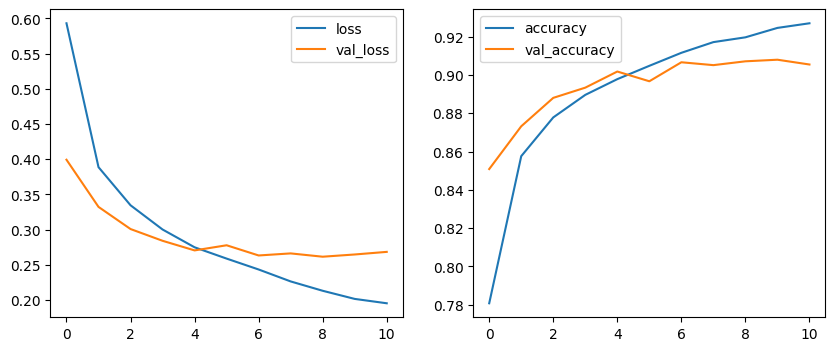

In [ ]:
fig,ax = plt.subplots(1,2,figsize = (10,4))
history_df = pd.DataFrame(history.history)
history_df[['loss','val_loss']].plot(kind = "line",ax=ax[0])
history_df[['accuracy','val_accuracy']].plot(kind = "line",ax=ax[1])


### Evaluate Model Performance on Test Data

In [ ]:
test_images_scaled = test_images_reshaped/255.0
predictions = model.predict(test_images_scaled)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


In [ ]:
# predicting the first five
predictions[0:5]

array([[7.5118084e-10, 1.2162720e-09, 9.0141011e-10, 2.9256537e-09,
        6.9743183e-10, 2.8658016e-05, 1.4242081e-09, 3.8120186e-05,
        2.2046346e-11, 9.9993318e-01],
       [7.5087833e-06, 1.3791291e-12, 9.9979734e-01, 3.5113874e-08,
        9.6597527e-05, 3.3252374e-12, 9.8621931e-05, 8.3067136e-13,
        1.0057377e-08, 9.5071468e-12],
       [1.6695851e-11, 9.9999994e-01, 1.3037283e-15, 1.4405809e-13,
        3.6636149e-15, 1.7033792e-18, 5.8371857e-13, 8.2587638e-22,
        1.7344794e-14, 2.4933979e-23],
       [1.2917461e-11, 9.9999994e-01, 4.7783458e-15, 6.2567746e-13,
        1.0164328e-13, 1.8823500e-18, 4.6897230e-12, 1.9604324e-21,
        1.3724630e-14, 7.3860100e-23],
       [1.6849999e-01, 6.6224635e-07, 1.1890904e-02, 4.2265162e-04,
        1.1921317e-03, 5.7016189e-07, 8.1798524e-01, 1.7168750e-08,
        7.7561872e-06, 2.8157537e-08]], dtype=float32)

In [ ]:
prediction_labels = np.argmax(predictions,axis = 1)
prediction_labels[:5]

array([9, 2, 1, 1, 6])

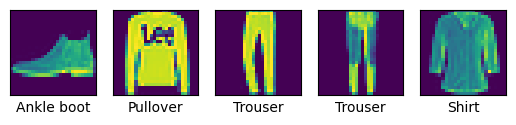

In [ ]:
# visualizing the test images
for i in range (5):
  plt.subplot(1,5,i+1)
  plt.xticks([])
  plt.yticks([])
  plt.grid(False)
  plt.imshow(test_images[i])
  plt.xlabel(class_names[prediction_labels[i]])
plt.show()

### Generating the Classification Report and Confusion Matrix

In [ ]:
from sklearn.metrics import confusion_matrix,classification_report
print(classification_report(test_labels,prediction_labels,target_names = class_names))


              precision    recall  f1-score   support

 T-shirt/top       0.82      0.88      0.85      1000
     Trouser       0.99      0.97      0.98      1000
    Pullover       0.88      0.81      0.84      1000
       Dress       0.91      0.90      0.90      1000
        Coat       0.82      0.89      0.85      1000
      Sandal       0.99      0.98      0.98      1000
       Shirt       0.72      0.67      0.70      1000
     Sneaker       0.94      0.97      0.96      1000
         Bag       0.96      0.97      0.97      1000
  Ankle boot       0.97      0.96      0.96      1000

    accuracy                           0.90     10000
   macro avg       0.90      0.90      0.90     10000
weighted avg       0.90      0.90      0.90     10000



### Fine-turning a pre-trained VGG-19 CNN Model

In [ ]:
train_images_3ch = np.stack([train_images]*3,axis = -1)
test_images_3ch = np.stack([test_images]*3,axis = -1)

### Resizing Image Data for Modelling

In [ ]:
import cv2
def resize_image_array(img, img_size_dims):
  img = cv2.resize(img, dsize=img_size_dims,
  interpolation=cv2.INTER_CUBIC)
  img = np.array(img, dtype=np.float32)
  return img

In [ ]:
%%time

IMG_DIMS = (32, 32)

train_images_3ch = np.array([resize_image_array(img, img_size_dims=IMG_DIMS) for img in train_images_3ch])
test_images_3ch = np.array([resize_image_array(img, img_size_dims=IMG_DIMS) for img in test_images_3ch])

print('\nTrain_images.shape: {}, of {}'.format(train_images_3ch.shape, train_images_3ch.dtype))
print('Test_images.shape: {}, of {}'.format(test_images_3ch.shape, test_images_3ch.dtype))


Train_images.shape: (60000, 32, 32, 3), of float32
Test_images.shape: (10000, 32, 32, 3), of float32
CPU times: user 1.64 s, sys: 377 ms, total: 2.02 s
Wall time: 2.27 s


## Build Cut-VGG19 Model

In [ ]:
INPUT_SHAPE = (32,32,3)
# get the VGG19 model
vgg_layers = tf.keras.applications.vgg19.VGG19(weights = "imagenet",include_top = False,input_shape = INPUT_SHAPE)
vgg_layers.summary()

Model: "vgg19"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)           │ (None, 32, 32, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block1_conv1 (Conv2D)                │ (None, 32, 32, 64)          │           1,792 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block1_conv2 (Conv2D)                │ (None, 32, 32, 64)          │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block1_pool (MaxPooling2D)           │ (None, 16, 16, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block2_conv1 (Conv2D)                │ (None, 16, 16, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block2_conv2 (Conv2D)                │ (None, 16, 16, 128)         │         147,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block2_pool (MaxPooling2D)           │ (None, 8, 8, 128)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_conv1 (Conv2D)                │ (None, 8, 8, 256)           │         295,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_conv2 (Conv2D)                │ (None, 8, 8, 256)           │         590,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_conv3 (Conv2D)                │ (None, 8, 8, 256)           │         590,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_conv4 (Conv2D)                │ (None, 8, 8, 256)           │         590,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_pool (MaxPooling2D)           │ (None, 4, 4, 256)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_conv1 (Conv2D)                │ (None, 4, 4, 512)           │       1,180,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_conv2 (Conv2D)                │ (None, 4, 4, 512)           │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_conv3 (Conv2D)                │ (None, 4, 4, 512)           │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_conv4 (Conv2D)                │ (None, 4, 4, 512)           │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_pool (MaxPooling2D)           │ (None, 2, 2, 512)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_conv1 (Conv2D)                │ (None, 2, 2, 512)           │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_conv2 (Conv2D)                │ (None, 2, 2, 512)           │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_conv3 (Conv2D)                │ (None, 2, 2, 512)           │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_conv4 (Conv2D)                │ (None, 2, 2, 512)           │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼──────────────

 Total params: 20,024,384 (76.39 MB)

 Trainable params: 20,024,384 (76.39 MB)

 Non-trainable params: 0 (0.00 B)

### Set layers to trainable to enable fine-tuning

In [ ]:
for layer in vgg_layers.layers:
  layer.trainable = True

### Build a CNN Model on top of VGG19

In [ ]:
model = tf.keras.models.Sequential()
model.add(vgg_layers)
# add flatten layer
model.add(tf.keras.layers.Flatten())
# add dense layers with some dropout
model.add(tf.keras.layers.Dense(256,activation = "relu"))
model.add(tf.keras.layers.Dropout(0.3))
model.add(tf.keras.layers.Dense(128,activation = "relu"))
model.add(tf.keras.layers.Dropout(0.3))
# add output layer
model.add(tf.keras.layers.Dense(10, activation = "softmax"))
#displaying model summary
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ vgg19 (Functional)                   │ (None, 1, 1, 512)           │      20,024,384 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_2 (Flatten)                  │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 256)                 │         131,328 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_4 (Dropout)                  │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_5 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_8 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 20,189,898 (77.02 MB)

 Trainable params: 20,189,898 (77.02 MB)

 Non-trainable params: 0 (0.00 B)

## Training our model using the PRetrained model

In [ ]:
model.compile(optimizer = "adam",loss = 'sparse_categorical_crossentropy',metrics = ["accuracy"])


In [ ]:
model.fit(train_images_3ch,train_labels,epochs = 50, callbacks=early_stopping, batch_size = 32,validation_split=0.1)


Epoch 1/50
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 124s 66ms/step - accuracy: 0.3860 - loss: 1.6863 - val_accuracy: 0.7915 - val_loss: 0.5653
Epoch 2/50
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 119s 57ms/step - accuracy: 0.7673 - loss: 0.6503 - val_accuracy: 0.8035 - val_loss: 0.5713
Epoch 3/50
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 141s 56ms/step - accuracy: 0.8146 - loss: 0.5477 - val_accuracy: 0.8355 - val_loss: 0.4407
Epoch 4/50
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 142s 56ms/step - accuracy: 0.8424 - loss: 0.4611 - val_accuracy: 0.8540 - val_loss: 0.4209
Epoch 5/50
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 96s 57ms/step - accuracy: 0.8454 - loss: 0.4697 - val_accuracy: 0.8638 - val_loss: 0.4076
Epoch 6/50
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 141s 56ms/step - accuracy: 0.8571 - loss: 0.4292 - val_accuracy: 0.8373 - val_loss: 0.4404
Epoch 7/50
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 96s 57ms/step - accuracy: 0.8559 - loss: 0.4191 - val_accuracy: 0.8717 - val_loss: 0.3957
Epoch 8/50
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 95s 57ms/step - accuracy: 0.8

<Axes: >

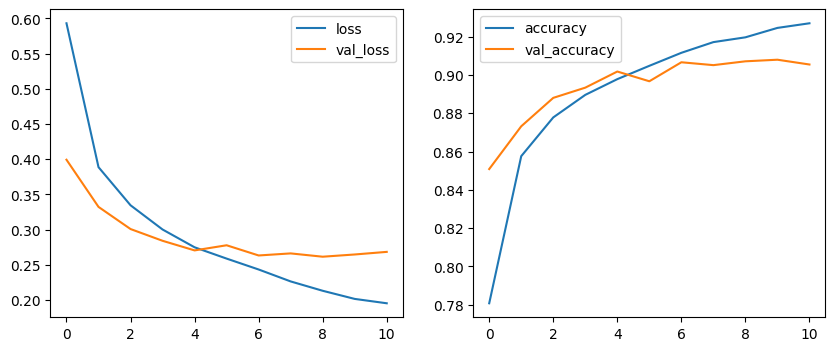

In [ ]:

fig,ax = plt.subplots(1,2,figsize=(10,4))
history_df = pd.DataFrame(history.history)
history_df[['loss','val_loss']].plot(kind = "line",ax = ax[0])
history_df[['accuracy','val_accuracy']].plot(kind = "line",ax = ax[1])

### Predicting using the pretrained model

In [ ]:
prediction = model.predict(test_images_3ch)
prediction_labels = np.argmax(prediction,axis = 1)
prediction_labels[:5]

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step


array([9, 2, 1, 1, 6])

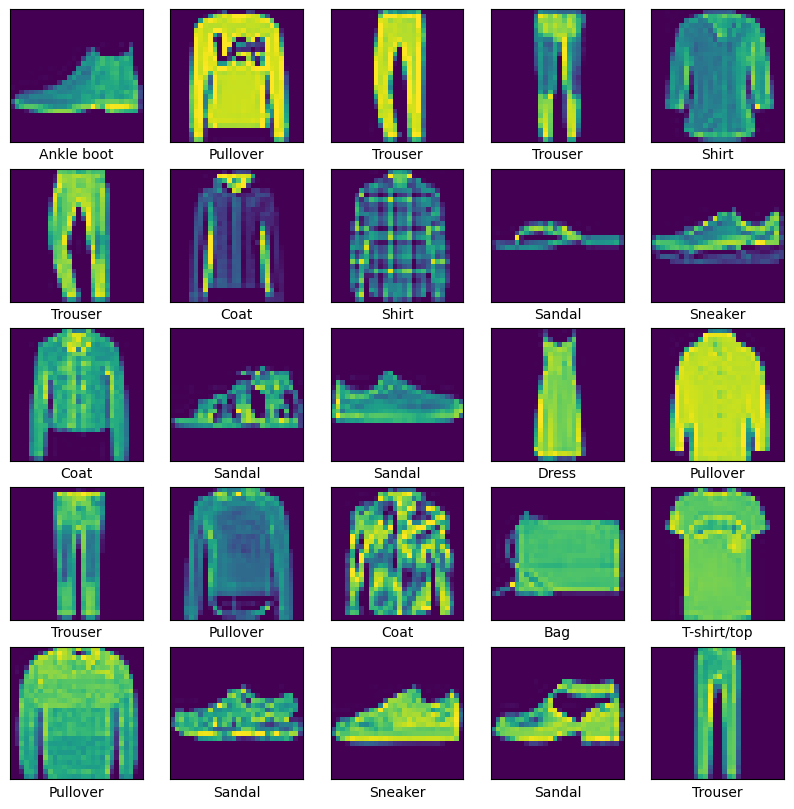

In [ ]:
# visualizing the first five predictions
plt.figure(figsize = (10,10))
for i in range(25):
  plt.subplot(5,5,i+1)
  plt.xticks([])
  plt.yticks([])
  plt.grid(False)
  plt.imshow(test_images[i])
  plt.xlabel(class_names[prediction_labels[i]])
plt.show()

### Model Evaluation

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
print(classification_report(test_labels,prediction_labels,target_names = class_names))

              precision    recall  f1-score   support

 T-shirt/top       0.88      0.76      0.81      1000
     Trouser       0.99      0.98      0.98      1000
    Pullover       0.77      0.85      0.80      1000
       Dress       0.91      0.86      0.89      1000
        Coat       0.80      0.70      0.75      1000
      Sandal       0.97      0.96      0.97      1000
       Shirt       0.61      0.73      0.67      1000
     Sneaker       0.97      0.90      0.93      1000
         Bag       0.96      0.97      0.97      1000
  Ankle boot       0.91      0.97      0.94      1000

    accuracy                           0.87     10000
   macro avg       0.88      0.87      0.87     10000
weighted avg       0.88      0.87      0.87     10000



In [ ]:
pd.DataFrame(confusion_matrix(test_labels,prediction_labels),columns=class_names, index = class_names)


,T-shirt/top,Trouser,Pullover,Dress,Coat,Sandal,Shirt,Sneaker,Bag,Ankle boot
T-shirt/top,761,1,4,21,4,1,201,0,7,0
Trouser,1,978,0,14,3,0,1,0,3,0
Pullover,5,1,847,8,50,0,89,0,0,0
Dress,13,4,7,862,61,1,48,0,4,0
Coat,0,1,168,10,703,0,117,0,1,0
Sandal,0,0,0,0,0,965,0,14,8,13
Shirt,89,1,79,26,58,0,733,0,14,0
Sneaker,0,0,0,0,0,16,0,904,0,80
Bag,0,0,1,2,4,7,12,0,974,0
Ankle boot,0,0,0,0,0,8,0,17,1,974
